In [ ]:
import pandas as pd

url = "https://www.openslr.org/resources/54/utt_spk_text.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["file_id", "speaker_id", "transcription"]
)

print("Total utterances:", len(df))
print("Unique speakers:", df["speaker_id"].nunique())

df.head()

Total utterances: 157905
Unique speakers: 527


,file_id,speaker_id,transcription
0,4aa1fdca33,6a6d1,००७ मिलको दूरीमा
1,86e521554a,1f680,००७ मिलको दूरीमा
2,c96b2b1afb,e349f,००७ मिलको दूरीमा
3,2f7ab41953,294d8,०११ देखि काङ्ग्रेसको
4,c290e5124b,88901,०१ सौर द्रव्यमान


In [ ]:
print(df.isnull().sum())

print("\n Speaker Distribution:")
print(df['speaker_id'].value_counts().describe())

print('\n Sample file IDs:')
print(df['file_id'].head(20).tolist())

file_id          0
speaker_id       0
transcription    0
dtype: int64

 Speaker Distribution:
count    527.000000
mean     299.629981
std       84.657202
min       13.000000
25%      259.500000
50%      311.000000
75%      350.000000
max      711.000000
Name: count, dtype: float64

 Sample file IDs:
['4aa1fdca33', '86e521554a', 'c96b2b1afb', '2f7ab41953', 'c290e5124b', '1d7f225bd0', '5e766d189e', '8190842174', 'b6c37578d2', 'c40938bd06', 'c89e1079c6', '2bedce5635', 'e4ed3e951c', '0ba8e6bacd', 'de4dc39a7a', '3ed2cee22b', '96cf842c07', 'a7f5ba44bb', '6c3b5fab5f', 'c977a4d3eb']


In [ ]:
# Check distribution of audio IDs by first character

df['prefix'] = df['file_id'].str[0]

prefix_counts = df["prefix"].value_counts().sort_index()

print(prefix_counts)

print("\n Total:", prefix_counts.sum())

prefix
0    9935
1    9841
2    9986
3    9760
4    9859
5    9700
6    9986
7    9984
8    9884
9    9828
a    9962
b    9855
c    9819
d    9969
e    9768
f    9769
Name: count, dtype: int64

 Total: 157905


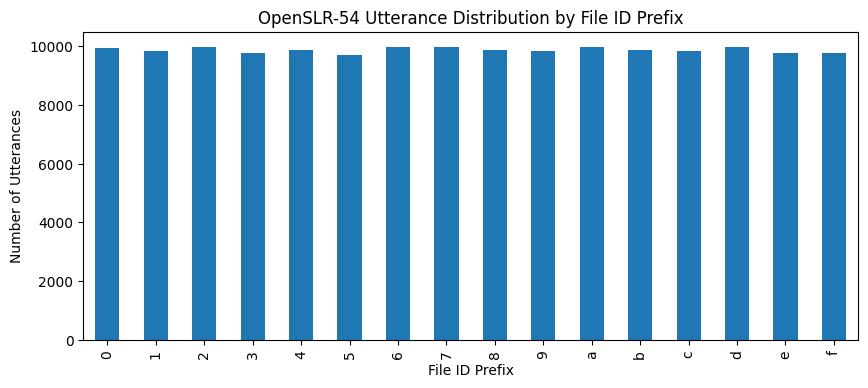

In [ ]:
import matplotlib.pyplot as plt

prefix_counts.plot(kind="bar", figsize=(10, 4))

plt.title("OpenSLR-54 Utterance Distribution by File ID Prefix")
plt.xlabel("File ID Prefix")
plt.ylabel("Number of Utterances")

plt.show()

In [ ]:
print("Duplicate file IDs:", df["file_id"].duplicated().sum())

print("Unique file IDs:", df["file_id"].nunique())

print("Total rows:", len(df))

Duplicate file IDs: 0
Unique file IDs: 157905
Total rows: 157905


In [ ]:
import requests

base_url = "https://www.openslr.org/resources/54/"

for i in "0123456789abcdef":
    filename = f"asr_nepali_{i}.zip"

    response = requests.head(base_url + filename)

    size_mb = int(response.headers.get("Content-Length", 0)) / (1024**2)

    print(filename, f"{size_mb:.1f} MB")

asr_nepali_0.zip 561.7 MB
asr_nepali_1.zip 555.1 MB
asr_nepali_2.zip 562.1 MB
asr_nepali_3.zip 548.0 MB
asr_nepali_4.zip 556.7 MB
asr_nepali_5.zip 546.4 MB
asr_nepali_6.zip 560.9 MB
asr_nepali_7.zip 561.2 MB
asr_nepali_8.zip 558.1 MB
asr_nepali_9.zip 552.0 MB
asr_nepali_a.zip 560.6 MB
asr_nepali_b.zip 557.3 MB
asr_nepali_c.zip 552.6 MB
asr_nepali_d.zip 561.2 MB
asr_nepali_e.zip 551.3 MB
asr_nepali_f.zip 550.9 MB


In [ ]:
import requests

url = "https://www.openslr.org/resources/54/asr_nepali_0.zip"

response = requests.get(
    url,
    headers={"Range": "bytes=0-1023"},
    stream=True
)

print("Status code:", response.status_code)
print("Content-Range:", response.headers.get("Content-Range"))
print("Accept-Ranges:", response.headers.get("Accept-Ranges"))

response.close()

Status code: 206
Content-Range: bytes 0-1023/589002210
Accept-Ranges: bytes


In [ ]:
!pip install -q remotezip

In [ ]:
from remotezip import RemoteZip

url = "https://www.openslr.org/resources/54/asr_nepali_0.zip"

with RemoteZip(url) as z:
    files = z.infolist()

    print("Total files:", len(files))

    for f in files[:15]:
        print(
            f.filename,
            f"{f.file_size / (1024**2):.2f} MB"
        )

Total files: 9953
asr_nepali/LICENSE 0.02 MB
asr_nepali/utt_spk_text.tsv 10.38 MB
asr_nepali/data/00/ 0.00 MB
asr_nepali/data/00/002bf0aab4.flac 0.05 MB
asr_nepali/data/00/00ee752d8d.flac 0.05 MB
asr_nepali/data/00/00e97d64b2.flac 0.08 MB
asr_nepali/data/00/003017eaca.flac 0.05 MB
asr_nepali/data/00/00ad922f03.flac 0.07 MB
asr_nepali/data/00/00c3495e71.flac 0.06 MB
asr_nepali/data/00/007b011c89.flac 0.06 MB
asr_nepali/data/00/0042d2b56d.flac 0.05 MB
asr_nepali/data/00/006a4b13b2.flac 0.06 MB
asr_nepali/data/00/006dcbf209.flac 0.10 MB
asr_nepali/data/00/00a9723f3b.flac 0.06 MB
asr_nepali/data/00/00014b6780.flac 0.04 MB


In [ ]:
from remotezip import RemoteZip
import os

archive_url = (
    "https://www.openslr.org/resources/54/asr_nepali_0.zip"
)

# Get a sample ID from your metadata
sample_id = str(df["file_id"].iloc[0])

# Expected location inside the ZIP
audio_path = (
    f"asr_nepali/data/{sample_id[:2]}/{sample_id}.flac"
)

with RemoteZip(archive_url) as z:

    audio_infos = [
        f for f in z.infolist()
        if f.filename.endswith(".flac")
    ]

    audio_names = {f.filename for f in audio_infos}

    print("Audio files in archive:", len(audio_infos))

    print(
        "Total extracted audio size:",
        round(sum(f.file_size for f in audio_infos) / (1024**3), 3),
        "GB"
    )

    print("Sample file ID:", sample_id)
    print("Expected audio path:", audio_path)
    print("Audio exists:", audio_path in audio_names)

Audio files in archive: 9935
Total extracted audio size: 0.537 GB
Sample file ID: 4aa1fdca33
Expected audio path: asr_nepali/data/4a/4aa1fdca33.flac
Audio exists: False


In [ ]:
from remotezip import RemoteZip

# Choose an ID belonging to archive 0
sample_id = str(
    df[df["file_id"].astype(str).str.startswith("0")]
    ["file_id"].iloc[0]
)

url = "https://www.openslr.org/resources/54/asr_nepali_0.zip"

audio_path = (
    f"asr_nepali/data/{sample_id[:2]}/{sample_id}.flac"
)

with RemoteZip(url) as z:
    names = set(z.namelist())

    print("File ID:", sample_id)
    print("Expected path:", audio_path)
    print("Audio exists:", audio_path in names)

File ID: 0ba8e6bacd
Expected path: asr_nepali/data/0b/0ba8e6bacd.flac
Audio exists: True


In [ ]:
import pandas as pd
from remotezip import RemoteZip

base_url = "https://www.openslr.org/resources/54/"

archive_stats = []

for prefix in "0123456789abcdef":

    url = f"{base_url}asr_nepali_{prefix}.zip"

    with RemoteZip(url) as z:
        audio = [
            f for f in z.infolist()
            if f.filename.endswith(".flac")
        ]

        archive_stats.append({
            "prefix": prefix,
            "audio_files": len(audio),
            "extracted_GB": sum(
                f.file_size for f in audio
            ) / (1024**3),
            "compressed_GB": sum(
                f.compress_size for f in audio
            ) / (1024**3)
        })

stats_df = pd.DataFrame(archive_stats)

display(stats_df)

print("Total audio files:", stats_df["audio_files"].sum())
print("Total extracted GB:", stats_df["extracted_GB"].sum())

,prefix,audio_files,extracted_GB,compressed_GB
0,0,9935,0.536580,0.536580
1,1,9841,0.530158,0.530158
2,2,9986,0.536942,0.536942
3,3,9760,0.523195,0.523195
4,4,9859,0.531699,0.531699
5,5,9700,0.521689,0.521689
6,6,9986,0.535734,0.535734
7,7,9984,0.536019,0.536019
8,8,9884,0.533041,0.533041
9,9,9828,0.527130,0.527130


Total audio files: 157905
Total extracted GB: 8.492771751247346


In [ ]:
import pandas as pd
from remotezip import RemoteZip

base_url = "https://www.openslr.org/resources/54/"

# Ensure IDs are strings
df["file_id"] = df["file_id"].astype(str)
df["speaker_id"] = df["speaker_id"].astype(str)

audio_records = []

for prefix in "0123456789abcdef":
    url = f"{base_url}asr_nepali_{prefix}.zip"

    with RemoteZip(url) as z:
        for f in z.infolist():

            if f.filename.endswith(".flac"):
                file_id = f.filename.split("/")[-1].replace(".flac", "")

                audio_records.append({
                    "file_id": file_id,
                    "archive_prefix": prefix,
                    "audio_path": f.filename,
                    "file_size": f.file_size,
                    "compressed_size": f.compress_size
                })

# Create manifest
audio_manifest = pd.DataFrame(audio_records)

# Join audio metadata with transcription and speaker information
manifest = df.merge(
    audio_manifest,
    on="file_id",
    how="inner"
)

print("Manifest records:", len(manifest))
print("Missing audio records:", len(df) - len(manifest))

manifest.head()

Manifest records: 157905
Missing audio records: 0


,file_id,speaker_id,transcription,prefix,archive_prefix,audio_path,file_size,compressed_size
0,4aa1fdca33,6a6d1,००७ मिलको दूरीमा,4,4,asr_nepali/data/4a/4aa1fdca33.flac,69624,69624
1,86e521554a,1f680,००७ मिलको दूरीमा,8,8,asr_nepali/data/86/86e521554a.flac,63753,63753
2,c96b2b1afb,e349f,००७ मिलको दूरीमा,c,c,asr_nepali/data/c9/c96b2b1afb.flac,59079,59079
3,2f7ab41953,294d8,०११ देखि काङ्ग्रेसको,2,2,asr_nepali/data/2f/2f7ab41953.flac,74347,74347
4,c290e5124b,88901,०१ सौर द्रव्यमान,c,c,asr_nepali/data/c2/c290e5124b.flac,54270,54270


In [ ]:
# Aggregate information for each speaker
speaker_stats = (
    manifest.groupby("speaker_id")
    .agg(
        utterances=("file_id", "count"),
        total_audio_bytes=("file_size", "sum")
    )
    .reset_index()
)

speaker_stats["audio_GB"] = (
    speaker_stats["total_audio_bytes"] / (1024 ** 3)
)

print("Unique speakers:", len(speaker_stats))
print("Average utterances per speaker:",
      round(speaker_stats["utterances"].mean(), 2))

print("\nUtterances per speaker:")
print(speaker_stats["utterances"].describe())

print("\nLargest speakers:")
display(
    speaker_stats.sort_values(
        "utterances", ascending=False
    ).head(10)
)

Unique speakers: 527
Average utterances per speaker: 299.63

Utterances per speaker:
count    527.000000
mean     299.629981
std       84.657202
min       13.000000
25%      259.500000
50%      311.000000
75%      350.000000
max      711.000000
Name: utterances, dtype: float64

Largest speakers:


,speaker_id,utterances,total_audio_bytes,audio_GB
72,24945,711,38835205,0.036168
226,6a6d1,663,36897548,0.034364
135,41d46,650,33743522,0.031426
306,90bdd,613,36595484,0.034082
178,55c0f,576,33534081,0.031231
384,ba807,518,35534061,0.033094
24,0d4f0,477,26390935,0.024578
157,4b59a,465,25525353,0.023772
274,8272f,463,23108601,0.021522
323,97b71,453,29061735,0.027066


In [ ]:
import numpy as np

# Overall speaker-level statistics
print("Total speakers:", len(speaker_stats))

print(
    "Total audio (GB):",
    round(speaker_stats["total_audio_bytes"].sum() / (1024**3), 3)
)

print("\nAudio size per speaker (GB):")

speaker_stats["audio_GB"] = (
    speaker_stats["total_audio_bytes"] / (1024**3)
)

print(
    speaker_stats["audio_GB"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

print("\nUtterances per speaker:")
print(
    speaker_stats["utterances"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    )
)

Total speakers: 527
Total audio (GB): 8.493

Audio size per speaker (GB):
count    527.000000
mean       0.016115
std        0.005186
min        0.000835
10%        0.009869
25%        0.013113
50%        0.016200
75%        0.019297
90%        0.021520
max        0.036168
Name: audio_GB, dtype: float64

Utterances per speaker:
count    527.000000
mean     299.629981
std       84.657202
min       13.000000
10%      194.400000
25%      259.500000
50%      311.000000
75%      350.000000
90%      378.400000
max      711.000000
Name: utterances, dtype: float64


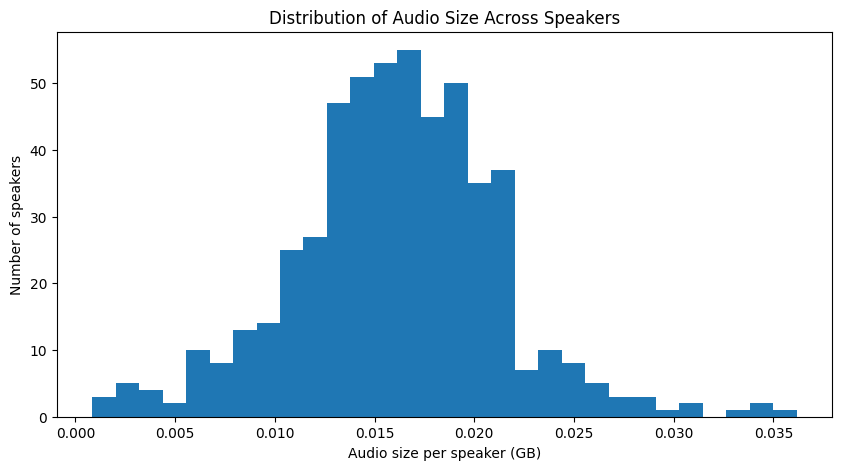

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(speaker_stats["audio_GB"], bins=30)
plt.xlabel("Audio size per speaker (GB)")
plt.ylabel("Number of speakers")
plt.title("Distribution of Audio Size Across Speakers")
plt.show()

In [ ]:
import os
import pandas as pd
from remotezip import RemoteZip

base_url = "https://www.openslr.org/resources/54/"

manifest_rows = []

for prefix in "0123456789abcdef":

    url = f"{base_url}asr_nepali_{prefix}.zip"

    print(f"Inspecting archive: {prefix}")

    with RemoteZip(url) as z:

        for info in z.infolist():

            if not info.filename.endswith(".flac"):
                continue

            file_id = os.path.basename(
                info.filename
            ).removesuffix(".flac")

            manifest_rows.append({
                "file_id": file_id,
                "archive_prefix": prefix,
                "archive_path": info.filename,
                "file_size": info.file_size,
                "compressed_size": info.compress_size
            })

manifest = pd.DataFrame(manifest_rows)

print("Total audio files:", len(manifest))
display(manifest.head())

Inspecting archive: 0
Inspecting archive: 1
Inspecting archive: 2
Inspecting archive: 3
Inspecting archive: 4
Inspecting archive: 5
Inspecting archive: 6
Inspecting archive: 7
Inspecting archive: 8
Inspecting archive: 9
Inspecting archive: a
Inspecting archive: b
Inspecting archive: c
Inspecting archive: d
Inspecting archive: e
Inspecting archive: f
Total audio files: 157905


,file_id,archive_prefix,archive_path,file_size,compressed_size
0,002bf0aab4,0,asr_nepali/data/00/002bf0aab4.flac,57483,57483
1,00ee752d8d,0,asr_nepali/data/00/00ee752d8d.flac,51006,51006
2,00e97d64b2,0,asr_nepali/data/00/00e97d64b2.flac,88851,88851
3,003017eaca,0,asr_nepali/data/00/003017eaca.flac,49947,49947
4,00ad922f03,0,asr_nepali/data/00/00ad922f03.flac,69904,69904


In [ ]:
df["file_id"] = df["file_id"].astype(str)

manifest = manifest.merge(
    df[["file_id", "speaker_id", "transcription"]],
    on="file_id",
    how="left",
    validate="one_to_one"
)

print("Missing speaker IDs:", manifest["speaker_id"].isna().sum())
print("Missing transcripts:", manifest["transcription"].isna().sum())

manifest["speaker_id"] = manifest["speaker_id"].astype(str)

print(
    "Total audio (GB):",
    round(manifest["file_size"].sum() / (1024**3), 3)
)

Missing speaker IDs: 0
Missing transcripts: 0
Total audio (GB): 8.493


In [ ]:
from remotezip import RemoteZip
import soundfile as sf
import os

sample_rows = manifest.sample(
    n=5,
    random_state=42
)

os.makedirs("/content/audio_samples", exist_ok=True)

for _, row in sample_rows.iterrows():

    url = (
        f"https://www.openslr.org/resources/54/"
        f"asr_nepali_{row['archive_prefix']}.zip"
    )

    with RemoteZip(url) as z:
        audio_bytes = z.read(row["archive_path"])

    output_path = (
        f"/content/audio_samples/{row['file_id']}.flac"
    )

    with open(output_path, "wb") as f:
        f.write(audio_bytes)

    info = sf.info(output_path)

    print("File:", row["file_id"])
    print("Sample rate:", info.samplerate)
    print("Channels:", info.channels)
    print("Duration:", round(info.duration, 2), "seconds")
    print("-" * 40)

File: 01c1eb642b
Sample rate: 16000
Channels: 1
Duration: 3.6 seconds
----------------------------------------
File: 5d18cf9c58
Sample rate: 16000
Channels: 1
Duration: 3.3 seconds
----------------------------------------
File: 8145c0f03d
Sample rate: 16000
Channels: 1
Duration: 15.5 seconds
----------------------------------------
File: 9567cc005b
Sample rate: 16000
Channels: 1
Duration: 3.3 seconds
----------------------------------------
File: cc9f91c077
Sample rate: 16000
Channels: 1
Duration: 2.7 seconds
----------------------------------------


In [ ]:
import soundfile as sf
import os
from remotezip import RemoteZip

sample_rows = manifest.sample(
    n=100,
    random_state=42
)

durations = []

for prefix, group in sample_rows.groupby("archive_prefix"):

    url = (
        f"https://www.openslr.org/resources/54/"
        f"asr_nepali_{prefix}.zip"
    )

    with RemoteZip(url) as z:

        for _, row in group.iterrows():

            audio_bytes = z.read(row["archive_path"])

            output_path = f"/content/temp.flac"

            with open(output_path, "wb") as f:
                f.write(audio_bytes)

            info = sf.info(output_path)

            durations.append({
                "file_id": row["file_id"],
                "duration": info.duration,
                "sample_rate": info.samplerate,
                "channels": info.channels
            })

duration_df = pd.DataFrame(durations)

display(duration_df.head())

print("\nDuration statistics:")
display(duration_df["duration"].describe())

print("\nSample rate distribution:")
print(duration_df["sample_rate"].value_counts())

print("\nChannel distribution:")
print(duration_df["channels"].value_counts())

,file_id,duration,sample_rate,channels
0,01c1eb642b,3.6,16000,1
1,06392bd4f2,5.2,16000,1
2,075e22fce6,2.4,16000,1
3,02e48b298a,3.4,16000,1
4,03eb21f71c,2.9,16000,1



Duration statistics:


,duration
count,100.000000
mean,3.783000
std,1.577945
min,2.000000
25%,2.900000
50%,3.500000
75%,4.225000
max,15.500000



Sample rate distribution:
sample_rate
16000    100
Name: count, dtype: int64

Channel distribution:
channels
1    100
Name: count, dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
print("Metadata:", df.shape)
print("Manifest:", manifest.shape)

print(
    "Missing speakers:",
    manifest["speaker_id"].isna().sum()
)

print(
    "Missing transcripts:",
    manifest["transcription"].isna().sum()
)

Metadata: (157905, 3)
Manifest: (157905, 7)
Missing speakers: 0
Missing transcripts: 0


In [ ]:
import os

print(os.listdir('/content/drive'))

['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Nepali_Whisper_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Folder created:", PROJECT_DIR)

Folder created: /content/drive/MyDrive/Nepali_Whisper_Project


In [ ]:
df.to_csv(
    f"{PROJECT_DIR}/metadata.csv",
    index=False,
    encoding="utf-8-sig"
)

manifest.to_csv(
    f"{PROJECT_DIR}/audio_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Project files saved!")

Project files saved!


In [ ]:
print(os.listdir(PROJECT_DIR))

['metadata.csv', 'audio_manifest.csv']


In [ ]:
import io

sample_rows = manifest.sample(
    n=100,
    random_state=42
)

print("Selected recordings:", len(sample_rows))

base_url = "https://www.openslr.org/resources/54/"

duration_results = []

for prefix, group in sample_rows.groupby("archive_prefix"):

    url = f"{base_url}asr_nepali_{prefix}.zip"

    print(f"Inspecting archive: {prefix}")

    with RemoteZip(url) as z:

        for _, row in group.iterrows():

            audio_bytes = z.read(row["archive_path"])

            info = sf.info(io.BytesIO(audio_bytes))

            duration_results.append({
                "file_id": row["file_id"],
                "speaker_id": row["speaker_id"],
                "duration": info.duration,
                "sample_rate": info.samplerate,
                "channels": info.channels
            })

duration_df = pd.DataFrame(duration_results)

print("\nInspection completed!")
print("Total recordings:", len(duration_df))

Selected recordings: 100
Inspecting archive: 0
Inspecting archive: 1
Inspecting archive: 2
Inspecting archive: 3
Inspecting archive: 4
Inspecting archive: 5
Inspecting archive: 6
Inspecting archive: 7
Inspecting archive: 8
Inspecting archive: 9
Inspecting archive: a
Inspecting archive: b
Inspecting archive: c
Inspecting archive: d
Inspecting archive: e
Inspecting archive: f

Inspection completed!
Total recordings: 100


In [ ]:
duration_df.to_csv(
    f"{PROJECT_DIR}/duration_sample.csv",
    index=False
)

print("Duration sample saved!")

Duration sample saved!


In [ ]:
print("Sample rate distribution:")
print(duration_df["sample_rate"].value_counts())

print("\nChannel distribution:")
print(duration_df["channels"].value_counts())

Sample rate distribution:
sample_rate
16000    100
Name: count, dtype: int64

Channel distribution:
channels
1    100
Name: count, dtype: int64


In [ ]:
display(duration_df["duration"].describe())

,duration
count,100.000000
mean,3.783000
std,1.577945
min,2.000000
25%,2.900000
50%,3.500000
75%,4.225000
max,15.500000


In [ ]:
sample_analysis = duration_df.merge(
    manifest[["file_id", "file_size"]],
    on="file_id",
    how="left"
)

print("Average duration (seconds):",
      sample_analysis["duration"].mean())

print("Average file size (MB):",
      sample_analysis["file_size"].mean() / (1024**2))

print("Estimated hours per GB:")

seconds_per_gb = (
    sample_analysis["duration"].sum()
    / sample_analysis["file_size"].sum()
    * (1024**3)
)

print(round(seconds_per_gb / 3600, 2), "hours")

Average duration (seconds): 3.783
Average file size (MB): 0.05830817222595215
Estimated hours per GB:
18.45 hours


In [ ]:
estimated_hours = (seconds_per_gb * 3) / 3600

print("Estimated speech hours in 3 GB:",
      round(estimated_hours, 2))

Estimated speech hours in 3 GB: 55.36


In [ ]:
duration_df["duration"].describe().to_csv(
    f"{PROJECT_DIR}/duration_statistics.csv"
)

In [ ]:
speaker_stats = (
    manifest.groupby("speaker_id")
    .agg(
        utterance_count=("file_id", "count"),
        total_audio_bytes=("file_size", "sum")
    )
    .reset_index()
)

speaker_stats["audio_GB"] = (
    speaker_stats["total_audio_bytes"] / (1024**3)
)

speaker_stats["avg_file_MB"] = (
    speaker_stats["total_audio_bytes"]
    / speaker_stats["utterance_count"]
    / (1024**2)
)

print("Total speakers:", len(speaker_stats))

display(speaker_stats.head())

Total speakers: 527


,speaker_id,utterance_count,total_audio_bytes,audio_GB,avg_file_MB
0,004e5,182,8421443,0.007843,0.044128
1,005e1,318,19752451,0.018396,0.059237
2,01173,284,18054628,0.016815,0.060628
3,01cf0,384,19652848,0.018303,0.048808
4,0234b,333,18243845,0.016991,0.052248


In [ ]:
display(
    speaker_stats[
        ["utterance_count", "audio_GB"]
    ].describe()
)

,utterance_count,audio_GB
count,527.000000,527.000000
mean,299.629981,0.016115
std,84.657202,0.005186
min,13.000000,0.000835
25%,259.500000,0.013113
50%,311.000000,0.016200
75%,350.000000,0.019297
max,711.000000,0.036168


In [ ]:
largest_speakers = speaker_stats.sort_values(
    "audio_GB",
    ascending=False
)

display(largest_speakers.head(15))

,speaker_id,utterance_count,total_audio_bytes,audio_GB,avg_file_MB
72,24945,711,38835205,0.036168,0.052090
226,6a6d1,663,36897548,0.034364,0.053074
306,90bdd,613,36595484,0.034082,0.056933
384,ba807,518,35534061,0.033094,0.065421
135,41d46,650,33743522,0.031426,0.049508
178,55c0f,576,33534081,0.031231,0.055522
428,ceb25,410,32264907,0.030049,0.075049
248,73d74,412,30352067,0.028268,0.070257
255,76dab,396,30094568,0.028028,0.072476
377,b77af,265,30032122,0.027970,0.108079


In [ ]:
speaker_stats.to_csv(
    f"{PROJECT_DIR}/speaker_statistics.csv",
    index=False
)

print("Speaker statistics saved to Google Drive!")

Speaker statistics saved to Google Drive!


Randomize the 527 speakers using a fixed random seed.



Select complete speaker groups, never individual recordings.



Allocate approximately 2.1 GB to training, 0.45 GB to validation, and 0.45 GB to testing.



Keep all speaker IDs exclusive to one split.



Save the final speaker assignments so every experiment uses exactly the same dataset.

we use a speaker-independent 70:15:15 split, with a fixed random seed.

However, rather than randomly assigning speakers and hoping the sizes match, we'll use a reproducible, size-aware allocation algorithm.

Our targets:
Split	Target audio
Training	2.10 GB
Validation	0.45 GB
Testing	0.45 GB
Total	3.00 GB

We'll prioritize:
1. No speaker overlap.
2. Approximately 3 GB total.
3. Reasonable speaker diversity.
4. Similar distribution of utterance counts and audio sizes where possible.

In [ ]:
import numpy as np

# Sort speakers by their actual audio contribution
speaker_stats = speaker_stats.sort_values(
    "total_audio_bytes",
    ascending=False
).reset_index(drop=True)

# Set reproducibility seed
SEED = 42

# Target sizes in bytes
GB = 1024 ** 3

targets = {
    "train": 2.10 * GB,
    "validation": 0.45 * GB,
    "test": 0.45 * GB
}

print("Target sizes:")
for split, size in targets.items():
    print(split, round(size / GB, 3), "GB")

print("\nSpeakers available:", len(speaker_stats))

Target sizes:
train 2.1 GB
validation 0.45 GB
test 0.45 GB

Speakers available: 527


In [ ]:
import numpy as np
import pandas as pd

SEED = 42
GB = 1024 ** 3

targets = {
    "train": int(2.10 * GB),
    "validation": int(0.45 * GB),
    "test": int(0.45 * GB)
}

# Ensure consistent speaker ID types
speaker_stats["speaker_id"] = speaker_stats["speaker_id"].astype(str)

# Randomize tie-breaking, then sort largest speakers first
speakers = speaker_stats.sample(
    frac=1,
    random_state=SEED
).sort_values(
    "total_audio_bytes",
    ascending=False
).reset_index(drop=True)

# Track allocated bytes
current_sizes = {split: 0 for split in targets}

assignments = []

for _, speaker in speakers.iterrows():

    speaker_id = speaker["speaker_id"]
    size = int(speaker["total_audio_bytes"])

    # Find splits where this complete speaker group fits
    eligible_splits = [
        split for split in targets
        if current_sizes[split] + size <= targets[split]
    ]

    if not eligible_splits:
        continue

    # Choose the split with the lowest relative utilization
    chosen_split = min(
        eligible_splits,
        key=lambda split: current_sizes[split] / targets[split]
    )

    assignments.append({
        "speaker_id": speaker_id,
        "split": chosen_split
    })

    current_sizes[chosen_split] += size

# Create assignment DataFrame
speaker_assignment = pd.DataFrame(assignments)

# Include unselected speakers for tracking
speaker_assignment = speaker_stats[
    ["speaker_id", "utterance_count", "total_audio_bytes"]
].merge(
    speaker_assignment,
    on="speaker_id",
    how="left"
)

speaker_assignment["split"] = (
    speaker_assignment["split"].fillna("unused")
)

print("Speaker assignment completed!")
print(speaker_assignment["split"].value_counts())

Speaker assignment completed!
split
unused        392
train          95
validation     20
test           20
Name: count, dtype: int64


In [ ]:
for split in ["train", "validation", "test", "unused"]:

    subset = speaker_assignment[
        speaker_assignment["split"] == split
    ]

    total_bytes = subset["total_audio_bytes"].sum()
    total_speakers = len(subset)
    total_utterances = subset["utterance_count"].sum()

    print(f"\n{split.upper()}")
    print(f"Speakers: {total_speakers}")
    print(f"Utterances: {total_utterances}")
    print(f"Audio size: {total_bytes / GB:.4f} GB")


TRAIN
Speakers: 95
Utterances: 34941
Audio size: 2.0998 GB

VALIDATION
Speakers: 20
Utterances: 7622
Audio size: 0.4498 GB

TEST
Speakers: 20
Utterances: 7495
Audio size: 0.4498 GB

UNUSED
Speakers: 392
Utterances: 107847
Audio size: 5.4933 GB


In [ ]:
# Check for speaker overlap
train_speakers = set(
    speaker_assignment.loc[
        speaker_assignment["split"] == "train", "speaker_id"
    ]
)

val_speakers = set(
    speaker_assignment.loc[
        speaker_assignment["split"] == "validation", "speaker_id"
    ]
)

test_speakers = set(
    speaker_assignment.loc[
        speaker_assignment["split"] == "test", "speaker_id"
    ]
)

print("Train ∩ Validation:", len(train_speakers & val_speakers))
print("Train ∩ Test:", len(train_speakers & test_speakers))
print("Validation ∩ Test:", len(val_speakers & test_speakers))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [ ]:
# Match speaker assignments with audio metadata
manifest["speaker_id"] = manifest["speaker_id"].astype(str)

selected_manifest = manifest.merge(
    speaker_assignment[["speaker_id", "split"]],
    on="speaker_id",
    how="inner",
    validate="many_to_one"
)

# Keep only selected speakers
selected_manifest = selected_manifest[
    selected_manifest["split"].isin(
        ["train", "validation", "test"]
    )
].copy()

# Create individual manifests
train_manifest = selected_manifest[
    selected_manifest["split"] == "train"
].copy()

val_manifest = selected_manifest[
    selected_manifest["split"] == "validation"
].copy()

test_manifest = selected_manifest[
    selected_manifest["split"] == "test"
].copy()

print("Train:", len(train_manifest))
print("Validation:", len(val_manifest))
print("Test:", len(test_manifest))

Train: 34941
Validation: 7622
Test: 7495


In [ ]:
speaker_assignment.to_csv(
    f"{PROJECT_DIR}/speaker_assignment.csv",
    index=False
)

train_manifest.to_csv(
    f"{PROJECT_DIR}/train_manifest.csv",
    index=False
)

val_manifest.to_csv(
    f"{PROJECT_DIR}/validation_manifest.csv",
    index=False
)

test_manifest.to_csv(
    f"{PROJECT_DIR}/test_manifest.csv",
    index=False
)

selected_manifest.to_csv(
    f"{PROJECT_DIR}/selected_manifest.csv",
    index=False
)

print("All manifests saved successfully!")

All manifests saved successfully!


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Nepali_Whisper_Project"

AUDIO_DIR = f"{PROJECT_DIR}/audio"

for split in ["train", "validation", "test"]:
    os.makedirs(f"{AUDIO_DIR}/{split}", exist_ok=True)

print("Folders created successfully!")

for split in ["train", "validation", "test"]:
    print(split, ":", f"{AUDIO_DIR}/{split}")

Folders created successfully!
train : /content/drive/MyDrive/Nepali_Whisper_Project/audio/train
validation : /content/drive/MyDrive/Nepali_Whisper_Project/audio/validation
test : /content/drive/MyDrive/Nepali_Whisper_Project/audio/test


In [ ]:
for split, split_df in {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest
}.items():

    print(f"\n{split.upper()}")
    print("Files:", len(split_df))
    print("Archive prefixes:", sorted(split_df["archive_prefix"].unique()))



TRAIN
Files: 34941
Archive prefixes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f']

VALIDATION
Files: 7622
Archive prefixes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f']

TEST
Files: 7495
Archive prefixes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f']


In [ ]:
import os
from remotezip import RemoteZip
from tqdm.auto import tqdm

BASE_URL = "https://www.openslr.org/resources/54/"

split_manifests = {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest
}

# Build a lookup of selected archive paths
selected_files = {}

for split, split_df in split_manifests.items():
    for _, row in split_df.iterrows():
        selected_files[row["archive_path"]] = {
            "split": split,
            "file_id": row["file_id"]
        }

print("Total selected files:", len(selected_files))

Total selected files: 50058


In [ ]:
import time

downloaded = 0
skipped = 0
failed = []

for prefix in "0123456789abcdef":

    url = f"{BASE_URL}asr_nepali_{prefix}.zip"

    print(f"\nProcessing archive: {prefix}")

    try:
        with RemoteZip(url) as z:

            archive_files = [
                info for info in z.infolist()
                if info.filename in selected_files
            ]

            print("Selected files:", len(archive_files))

            for info in tqdm(archive_files):

                details = selected_files[info.filename]

                split = details["split"]
                file_id = details["file_id"]

                output_path = (
                    f"{AUDIO_DIR}/{split}/{file_id}.flac"
                )

                # Skip already downloaded files
                if os.path.exists(output_path):
                    skipped += 1
                    continue

                try:
                    audio_bytes = z.read(info.filename)

                    with open(output_path, "wb") as f:
                        f.write(audio_bytes)

                    downloaded += 1

                except Exception as e:
                    failed.append({
                        "file_id": file_id,
                        "archive_path": info.filename,
                        "error": str(e)
                    })

    except Exception as e:
        print(f"Archive {prefix} failed:", e)

print("\nDOWNLOAD SUMMARY")
print("Downloaded:", downloaded)
print("Skipped:", skipped)
print("Failed:", len(failed))


Processing archive: 0
Selected files: 3143


  0%|          | 0/3143 [00:00<?, ?it/s]


Processing archive: 1
Selected files: 3162


  0%|          | 0/3162 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
import shutil

disk = shutil.disk_usage("/content")

print(f"Total: {disk.total / (1024**3):.2f} GB")
print(f"Used: {disk.used / (1024**3):.2f} GB")
print(f"Free: {disk.free / (1024**3):.2f} GB")

Total: 107.72 GB
Used: 0.38 GB
Free: 107.32 GB


In [ ]:
import os

for split in ["train", "validation", "test"]:
    folder = f"{AUDIO_DIR}/{split}"

    count = len([
        f for f in os.listdir(folder)
        if f.endswith(".flac")
    ])

    print(split, ":", count)

train : 2286
validation : 531
test : 487


In [ ]:
import os
import zipfile
import requests
from tqdm.auto import tqdm

TEMP_DIR = "/content/openslr_archives"
os.makedirs(TEMP_DIR, exist_ok=True)

# Build archive-prefix lookup
archive_lookup = {}

for split, split_df in {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest
}.items():

    for _, row in split_df.iterrows():
        archive_lookup[row["archive_path"]] = {
            "split": split,
            "file_id": row["file_id"]
        }

print("Selected files:", len(archive_lookup))
print("Temporary directory:", TEMP_DIR)

Selected files: 50058
Temporary directory: /content/openslr_archives


In [ ]:
import os
import re
import zipfile
import requests
import pandas as pd
from tqdm.auto import tqdm

BASE_URL = "https://www.openslr.org/resources/54/"
TEMP_DIR = "/content/openslr_archives"
PROGRESS_FILE = f"{PROJECT_DIR}/download_progress.csv"

os.makedirs(TEMP_DIR, exist_ok=True)


def download_with_resume(url, part_path):
    """Download a ZIP while preserving partial progress."""

    while True:
        offset = os.path.getsize(part_path) if os.path.exists(part_path) else 0

        headers = {}
        if offset > 0:
            headers["Range"] = f"bytes={offset}-"

        print(f"Already downloaded: {offset / (1024**2):.2f} MB")

        with requests.get(
            url,
            headers=headers,
            stream=True,
            timeout=(30, 180)
        ) as response:

            # Handle a server that says the requested range is invalid.
            if response.status_code == 416:
                try:
                    with zipfile.ZipFile(part_path, "r") as z:
                        z.infolist()
                    print("Existing partial file is already a valid ZIP.")
                    return
                except Exception:
                    if os.path.exists(part_path):
                        os.remove(part_path)
                    continue

            response.raise_for_status()

            if response.status_code == 206:
                content_range = response.headers.get("Content-Range", "")
                match = re.match(r"bytes (\d+)-(\d+)/(\d+)", content_range)

                if not match:
                    raise RuntimeError("Invalid Content-Range response.")

                actual_start = int(match.group(1))
                total_size = int(match.group(3))

                if actual_start != offset:
                    raise RuntimeError(
                        f"Range mismatch: expected {offset}, got {actual_start}"
                    )

                mode = "ab" if offset > 0 else "wb"

            elif response.status_code == 200:
                # Server ignored Range: restart this ZIP from the beginning.
                print("Server did not resume; restarting this archive.")
                offset = 0
                mode = "wb"
                total_size = int(response.headers.get("Content-Length", 0))

            else:
                raise RuntimeError(
                    f"Unexpected HTTP status: {response.status_code}"
                )

            with open(part_path, mode) as f:
                with tqdm(
                    total=total_size,
                    initial=offset,
                    unit="B",
                    unit_scale=True,
                    desc="Downloading"
                ) as pbar:

                    for chunk in response.iter_content(
                        chunk_size=4 * 1024 * 1024
                    ):
                        if chunk:
                            f.write(chunk)
                            pbar.update(len(chunk))

        actual_size = os.path.getsize(part_path)

        if total_size and actual_size != total_size:
            raise IOError(
                f"Incomplete download: {actual_size} of {total_size} bytes. "
                "Rerun this cell to resume."
            )

        # Check that the ZIP central directory can be read.
        with zipfile.ZipFile(part_path, "r") as z:
            z.infolist()

        return


In [ ]:
archive_lookup = {}

for split, split_df in {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest
}.items():

    for _, row in split_df.iterrows():
        archive_lookup[row["archive_path"]] = {
            "split": split,
            "file_id": str(row["file_id"]),
            "expected_size": int(row["file_size"])
        }

print("Selected files:", len(archive_lookup))

Selected files: 50058


In [ ]:
completed_archives = []

for prefix in "0123456789abcdef":

    archive_name = f"asr_nepali_{prefix}.zip"
    archive_path = f"{TEMP_DIR}/{archive_name}"
    part_path = archive_path + ".part"
    url = BASE_URL + archive_name

    print(f"\n{'='*50}")
    print(f"Processing archive: {prefix}")
    print(f"{'='*50}")

    # Correctly filter using the manifest's archive_prefix column.
    prefix_df = selected_manifest[
        selected_manifest["archive_prefix"].astype(str) == prefix
    ]

    expected_files = {
        row["archive_path"]: {
            "split": row["split"],
            "file_id": str(row["file_id"]),
            "expected_size": int(row["file_size"])
        }
        for _, row in prefix_df.iterrows()
    }

    if not expected_files:
        print("No selected recordings in this archive. Skipping.")
        continue

    print("Selected recordings:", len(expected_files))

    if not os.path.exists(archive_path):
        download_with_resume(url, part_path)
        os.replace(part_path, archive_path)

    with zipfile.ZipFile(archive_path, "r") as z:

        archive_members = {
            info.filename: info
            for info in z.infolist()
        }

        missing = set(expected_files) - set(archive_members)

        if missing:
            raise RuntimeError(
                f"{len(missing)} selected files missing from ZIP."
            )

        for archive_file in tqdm(expected_files, desc=f"Extracting {prefix}"):

            details = expected_files[archive_file]

            output_dir = f"{AUDIO_DIR}/{details['split']}"
            os.makedirs(output_dir, exist_ok=True)

            output_path = f"{output_dir}/{details['file_id']}.flac"
            temp_output = output_path + ".part"

            if os.path.exists(output_path):
                if os.path.getsize(output_path) == details["expected_size"]:
                    continue
                os.remove(output_path)

            if os.path.exists(temp_output):
                os.remove(temp_output)

            with z.open(archive_members[archive_file]) as src:
                with open(temp_output, "wb") as dst:
                    while True:
                        chunk = src.read(1024 * 1024)
                        if not chunk:
                            break
                        dst.write(chunk)

            if os.path.getsize(temp_output) != details["expected_size"]:
                os.remove(temp_output)
                raise IOError(f"Size mismatch: {details['file_id']}")

            os.replace(temp_output, output_path)

    completed_archives.append(prefix)

    pd.DataFrame({
        "completed_archive": completed_archives
    }).to_csv(PROGRESS_FILE, index=False)

    os.remove(archive_path)

    print(f"Archive {prefix} completed successfully!")

print("\nArchive processing finished!")


Processing archive: 0
Selected recordings: 3143
Already downloaded: 0.00 MB
Server did not resume; restarting this archive.


Downloading:   0%|          | 0.00/589M [00:00<?, ?B/s]

Extracting 0:   0%|          | 0/3143 [00:00<?, ?it/s]

Archive 0 completed successfully!

Processing archive: 1
Selected recordings: 3162
Already downloaded: 0.00 MB
Server did not resume; restarting this archive.


Downloading:   0%|          | 0.00/582M [00:00<?, ?B/s]

Extracting 1:   0%|          | 0/3162 [00:00<?, ?it/s]

... (39 outputs left out)

Archive e completed successfully!

Processing archive: f
Selected recordings: 3095
Already downloaded: 0.00 MB
Server did not resume; restarting this archive.


Downloading:   0%|          | 0.00/578M [00:00<?, ?B/s]

Extracting f:   0%|          | 0/3095 [00:00<?, ?it/s]

Archive f completed successfully!

Archive processing finished!


In [ ]:
import os

for split, expected in {
    "train": len(train_manifest),
    "validation": len(val_manifest),
    "test": len(test_manifest)
}.items():

    folder = f"{AUDIO_DIR}/{split}"

    actual = len([
        f for f in os.listdir(folder)
        if f.endswith(".flac")
    ]) if os.path.exists(folder) else 0

    print(f"{split}: {actual:,} / {expected:,}")

train: 34,941 / 34,941
validation: 7,622 / 7,622
test: 7,495 / 7,495


In [ ]:
import os
import pandas as pd

split_manifests = {
    "train": train_manifest,
    "validation": val_manifest,
    "test": test_manifest
}

verification_results = []

for split, split_df in split_manifests.items():

    missing = []
    size_mismatch = []

    for _, row in split_df.iterrows():

        path = f"{AUDIO_DIR}/{split}/{row['file_id']}.flac"

        if not os.path.exists(path):
            missing.append(row["file_id"])
            continue

        actual_size = os.path.getsize(path)
        expected_size = int(row["file_size"])

        if actual_size != expected_size:
            size_mismatch.append(row["file_id"])

    verification_results.append({
        "split": split,
        "expected_files": len(split_df),
        "missing_files": len(missing),
        "size_mismatches": len(size_mismatch),
        "audio_GB": split_df["file_size"].sum() / (1024**3)
    })

verification_df = pd.DataFrame(verification_results)

print(verification_df.to_string(index=False))
print("\nTotal dataset size (GB):",
      round(verification_df["audio_GB"].sum(), 4))

     split  expected_files  missing_files  size_mismatches  audio_GB
     train           34941              0                0  2.099846
validation            7622              0                0  0.449813
      test            7495              0                0  0.449819

Total dataset size (GB): 2.9995


In [ ]:
import os
import soundfile as sf
from tqdm.auto import tqdm

split_folders = ["train", "validation", "test"]

corrupted_files = []
checked_files = 0

for split in split_folders:

    folder = f"{AUDIO_DIR}/{split}"

    files = [
        f for f in os.listdir(folder)
        if f.endswith(".flac")
    ]

    print(f"\nChecking {split}: {len(files)} files")

    for filename in tqdm(files, desc=split):

        filepath = os.path.join(folder, filename)

        try:
            # Decode the audio file
            with sf.SoundFile(filepath) as audio:
                frames = len(audio)
                sample_rate = audio.samplerate
                channels = audio.channels

                if frames == 0 or sample_rate <= 0:
                    raise ValueError("Invalid audio properties")

            checked_files += 1

        except Exception as e:
            corrupted_files.append({
                "split": split,
                "file": filename,
                "error": str(e)
            })

print("\n========== RESULTS ==========")
print("Successfully checked:", checked_files)
print("Corrupted files:", len(corrupted_files))


Checking train: 34941 files


train:   0%|          | 0/34941 [00:00<?, ?it/s]


Checking validation: 7622 files


validation:   0%|          | 0/7622 [00:00<?, ?it/s]


Checking test: 7495 files


test:   0%|          | 0/7495 [00:00<?, ?it/s]


========== RESULTS ==========
Successfully checked: 50058
Corrupted files: 0


In [ ]:
import os
import soundfile as sf
import pandas as pd
from tqdm.auto import tqdm

audio_properties = []

for split in ["train", "validation", "test"]:

    folder = f"{AUDIO_DIR}/{split}"

    files = [
        f for f in os.listdir(folder)
        if f.endswith(".flac")
    ]

    for filename in tqdm(files, desc=f"Checking {split}"):

        filepath = os.path.join(folder, filename)

        with sf.SoundFile(filepath) as audio:
            audio_properties.append({
                "file": filename,
                "split": split,
                "sample_rate": audio.samplerate,
                "channels": audio.channels,
                "duration": len(audio) / audio.samplerate
            })

audio_df = pd.DataFrame(audio_properties)

print("\nSample rate distribution:")
print(audio_df["sample_rate"].value_counts())

print("\nChannel distribution:")
print(audio_df["channels"].value_counts())

print("\nDuration statistics:")
print(audio_df["duration"].describe())

audio_df.to_csv(
    f"{PROJECT_DIR}/audio_quality_report.csv",
    index=False
)

Checking train:   0%|          | 0/34941 [00:00<?, ?it/s]

Checking validation:   0%|          | 0/7622 [00:00<?, ?it/s]

Checking test:   0%|          | 0/7495 [00:00<?, ?it/s]


Sample rate distribution:
sample_rate
16000    50058
Name: count, dtype: int64

Channel distribution:
channels
1    50058
Name: count, dtype: int64

Duration statistics:
count    50058.000000
mean         3.921617
std          1.301497
min          1.500000
25%          3.100000
50%          3.700000
75%          4.400000
max         28.200000
Name: duration, dtype: float64


In [ ]:
import pandas as pd

# Work with the selected 50,058 recordings
text_df = selected_manifest[
    ["file_id", "speaker_id", "transcription", "split"]
].copy()

# Check missing and empty transcriptions
text_df["transcription"] = text_df["transcription"].fillna("").astype(str)

text_df["clean_text"] = text_df["transcription"].str.strip()

missing_text = (text_df["clean_text"] == "").sum()

# Check duplicate file IDs and duplicate transcription strings
duplicate_ids = text_df["file_id"].duplicated().sum()

duplicate_transcripts = (
    text_df["clean_text"].duplicated(keep=False)
    & (text_df["clean_text"] != "")
).sum()

# Calculate text lengths
text_df["char_length"] = text_df["clean_text"].str.len()
text_df["word_count"] = text_df["clean_text"].str.split().str.len()

print("========== TRANSCRIPTION QUALITY ==========")

print("Total recordings:", len(text_df))
print("Missing/empty transcriptions:", missing_text)
print("Duplicate file IDs:", duplicate_ids)
print("Rows with repeated transcription:", duplicate_transcripts)

print("\nCharacter length statistics:")
print(text_df["char_length"].describe())

print("\nWord count statistics:")
print(text_df["word_count"].describe())

print("\nShortest transcriptions:")
print(
    text_df.nsmallest(10, "char_length")[
        ["file_id", "transcription", "char_length"]
    ].to_string(index=False)
)

print("\nLongest transcriptions:")
print(
    text_df.nlargest(10, "char_length")[
        ["file_id", "transcription", "char_length"]
    ].to_string(index=False)
)

# Save report
text_df.to_csv(
    f"{PROJECT_DIR}/transcription_quality_report.csv",
    index=False
)

========== TRANSCRIPTION QUALITY ==========
Total recordings: 50058
Missing/empty transcriptions: 0
Duplicate file IDs: 0
Rows with repeated transcription: 17483

Character length statistics:
count    50058.000000
mean        18.462444
std          7.743116
min          1.000000
25%         14.000000
50%         18.000000
75%         21.000000
max        119.000000
Name: char_length, dtype: float64

Word count statistics:
count    50058.000000
mean         2.967198
std          1.037639
min          1.000000
25%          3.000000
50%          3.000000
75%          3.000000
max         15.000000
Name: word_count, dtype: float64

Shortest transcriptions:
   file_id transcription  char_length
3d1ab2b4bb             र            1
126c178e32          नकुल            4
12fccaefc6          नगरा            4
1749421fc0          काली            4
289fc398fb          यसले            4
55259e39ee          नगरा            4
7b9949c9e6          विजय            4
7dfcea72ed          नगरा           

In [ ]:
# Group recordings by exact transcription
duplicate_groups = (
    text_df[text_df["clean_text"] != ""]
    .groupby("clean_text")
    .agg(
        recordings=("file_id", "count"),
        speakers=("speaker_id", "nunique")
    )
    .reset_index()
)

repeated_groups = duplicate_groups[
    duplicate_groups["recordings"] > 1
].sort_values("recordings", ascending=False)

print("Unique transcription groups:", len(duplicate_groups))
print("Repeated transcription groups:", len(repeated_groups))
print("Recordings belonging to repeated groups:",
      repeated_groups["recordings"].sum())

print("\nMost repeated transcriptions:")
print(repeated_groups.head(15).to_string(index=False))

Unique transcription groups: 40654
Repeated transcription groups: 8079
Recordings belonging to repeated groups: 17483

Most repeated transcriptions:
                clean_text  recordings  speakers
       यसलाई इलेक्ट्रिक रे           5         5
       चुनाव भारत निर्वाचन           5         5
   ब्याज तिर्नुपर्ने हुन्छ           5         5
         प्यार्जुङ नेपालको           5         5
           काम गरेकी थिइन्           5         5
     सम्बोधन गर्ने त्यसैले           5         5
       एउटा ठाउँदेखि अर्को           5         5
ज्योतिष विज्ञानलाई विभिन्न           5         5
            बच्न सफल रह्यो           5         5
          केही वर्ष त मैले           5         5
           भने सन् २००६ मै           5         5
              लागि के गरेँ           5         5
         पहिलो क्याम्पस हो           4         4
             प्रयोग गरिनेछ           4         3
            उनी देवता हुन्           4         4


In [ ]:
same_speaker_duplicates = (
    text_df[text_df["clean_text"] != ""]
    .groupby(["speaker_id", "clean_text"])
    .agg(recordings=("file_id", "count"))
    .reset_index()
)

same_speaker_duplicates = same_speaker_duplicates[
    same_speaker_duplicates["recordings"] > 1
]

print("Same-speaker repeated transcript groups:",
      len(same_speaker_duplicates))

print("\nExamples:")
print(
    same_speaker_duplicates
    .sort_values("recordings", ascending=False)
    .head(15)
    .to_string(index=False)
)

Same-speaker repeated transcript groups: 29

Examples:
speaker_id                  clean_text  recordings
     12f3b               बनावटको हुन्छ           2
     24945       आफ्नो आदर्शवादी कविता           2
     24945           जसको उपयोग आकाशीय           2
     24945    पृथ्वीमा दबिएको कार्बनमा           2
     44903            नेपालको इतिहास र           2
     4b22c               विरोध गरे पनि           2
     6323a गर्दा अस्ट्रेलियाली सरकारले           2
     6a6d1           यो मुद्दाको फैसला           2
     7ed61               प्रयोग गरिनेछ           2
     8f426          सर्वव्यापी ईश्वरले           2
     90bdd                   आशय के हो           2
     90bdd       किपट प्रणाली अन्तर्गत           2
     970ca   मुसिकोट प्युठानका अनुयायी           2
     97b71        टाढा फ्याँकिदिन्छ तर           2
     a2ab6              शमीको रूख रोपे           2


In [ ]:
import hashlib
import os

def get_hash(filepath):
    sha = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


identical_audio = []

for _, group in text_df.groupby(["speaker_id", "clean_text"]):

    if len(group) <= 1 or group["clean_text"].iloc[0] == "":
        continue

    hashes = []

    for _, row in group.iterrows():
        path = (
            f"{AUDIO_DIR}/{row['split']}/"
            f"{row['file_id']}.flac"
        )

        hashes.append(get_hash(path))

    if len(set(hashes)) == 1:
        identical_audio.append({
            "speaker_id": group["speaker_id"].iloc[0],
            "transcription": group["clean_text"].iloc[0],
            "recordings": len(group)
        })

print("Identical audio groups:", len(identical_audio))
print(pd.DataFrame(identical_audio).to_string(index=False))

Identical audio groups: 0
Empty DataFrame
Columns: []
Index: []


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Nepali_Whisper_Project"

for filename in [
    "audio_quality_report.csv",
    "transcription_quality_report.csv"
]:
    path = os.path.join(PROJECT_DIR, filename)

    if os.path.exists(path):
        print(f"Found: {filename}")
        print(f"Size: {os.path.getsize(path) / 1024:.2f} KB")
    else:
        print(f"NOT FOUND: {filename}")

Found: audio_quality_report.csv
Size: 1692.34 KB
Found: transcription_quality_report.csv
Size: 6525.91 KB


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Nepali_Whisper_Project"

print("Drive mounted:", os.path.ismount("/content/drive"))
print("Project folder exists:", os.path.isdir(PROJECT_DIR))
print("\nFiles physically visible to Colab:")

!ls -lh "/content/drive/MyDrive/Nepali_Whisper_Project/audio_quality_report.csv"
!ls -lh "/content/drive/MyDrive/Nepali_Whisper_Project/transcription_quality_report.csv"

Drive mounted: True
Project folder exists: True

Files physically visible to Colab:
-rw------- 1 root root 1.7M Nov  8 10:55 /content/drive/MyDrive/Nepali_Whisper_Project/audio_quality_report.csv
-rw------- 1 root root 6.4M Nov  8 10:56 /content/drive/MyDrive/Nepali_Whisper_Project/transcription_quality_report.csv


In [ ]:
!ls -lah "/content/drive/MyDrive/Nepali_Whisper_Project"

total 49M
drwx------ 3 root root 4.0K Nov  8 10:56 .
drwx------ 4 root root 4.0K Nov  8 08:26 ..
drwx------ 5 root root 4.0K Nov  8 09:16 audio
-rw------- 1 root root  18M Nov  8 08:28 audio_manifest.csv
-rw------- 1 root root 1.7M Nov  8 10:55 audio_quality_report.csv
-rw------- 1 root root   50 Nov  8 10:40 download_progress.csv
-rw------- 1 root root 2.9K Nov  8 09:03 duration_sample.csv
-rw------- 1 root root   99 Nov  8 09:04 duration_statistics.csv
-rw------- 1 root root  11M Nov  8 08:28 metadata.csv
-rw------- 1 root root 6.0M Nov  8 09:15 selected_manifest.csv
-rw------- 1 root root  14K Nov  8 09:15 speaker_assignment.csv
-rw------- 1 root root  31K Nov  8 09:05 speaker_statistics.csv
-rw------- 1 root root 905K Nov  8 09:15 test_manifest.csv
-rw------- 1 root root 4.2M Nov  8 09:15 train_manifest.csv
-rw------- 1 root root 6.4M Nov  8 10:56 transcription_quality_report.csv
-rw------- 1 root root 968K Nov  8 09:15 validation_manifest.csv


In [ ]:
test_path = f"{PROJECT_DIR}/drive_sync_test.txt"

with open(test_path, "w") as f:
    f.write("Google Drive synchronization test")

print("Test file created:", os.path.exists(test_path))

Test file created: True


In [ ]:
import shutil
import os

shutil.copy2(
    f"{PROJECT_DIR}/audio_quality_report.csv",
    f"{PROJECT_DIR}/audio_quality_report_backup.csv"
)

shutil.copy2(
    f"{PROJECT_DIR}/transcription_quality_report.csv",
    f"{PROJECT_DIR}/transcription_quality_report_backup.csv"
)

print("Copies created successfully.")

Copies created successfully.
